# 01 — Exploratory data analysis: daily demand panel

This notebook profiles the synthetic Asviin demand panel that feeds the forecasting
layer. It is read-only: it reads the ETL output and never writes data or artifacts.

**Input:** `data/processed/demand_daily.csv` — one row per
`(date, business_id, branch_id, product_id)`, zero-filled when there was no sale.
The column contract and validations live in `src/data_contracts/schemas.py` and
`src/data_contracts/validation.py`; the notebook loads the file through
`src.data_contracts.load_csv` so the canonical contract is checked on every run.

**Prerequisites**

```bash
make data   # regenerate raw CSVs + ETL output (only if the committed data is missing)
```

**Contents**

1. Panel overview and quality checks
2. Weekly and annual seasonality
3. ABC / XYZ portfolio analysis
4. Zero-sale share by demand pattern
5. Pending orders and cancellations
6. Findings for inventory policy

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd

REPO_ROOT = next(
    (
        candidate
        for candidate in (Path.cwd(), *Path.cwd().parents)
        if (candidate / "src" / "data_contracts").is_dir()
    ),
    None,
)
if REPO_ROOT is None:
    raise RuntimeError(
        "Cannot locate the repository root. Start Jupyter from the repository root "
        "or from notebooks/ so that src/ is visible."
    )
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data_contracts import load_csv  # noqa: E402  (import after sys.path setup)

DATA_PATH = REPO_ROOT / "data" / "processed" / "demand_daily.csv"
print(f"Repository root: {REPO_ROOT.name}")
print(f"Demand panel:    {DATA_PATH.relative_to(REPO_ROOT)}")

Repository root: asviin-ml-forecasting
Demand panel:    data/processed/demand_daily.csv


## 0. Plotting dependency

Matplotlib is optional for this project, so the import is guarded. If it is missing,
the notebook keeps working and prints the tables instead of the charts.

In [2]:
try:
    import matplotlib.pyplot as plt

    MATPLOTLIB_AVAILABLE = True
except ImportError:
    plt = None
    MATPLOTLIB_AVAILABLE = False

MATPLOTLIB_HINT = (
    "matplotlib is not installed, so charts are skipped and tables are printed "
    "instead. Install it with `pip install matplotlib` "
    "(or `.venv/bin/pip install matplotlib`) and re-run this cell."
)

COLOR_MAIN = "#2f6f8f"
COLOR_ACCENT = "#d9822b"
COLOR_MUTED = "#8a8a8a"


def plots_available() -> bool:
    # True when matplotlib can render; otherwise print an actionable hint.
    if not MATPLOTLIB_AVAILABLE:
        print(MATPLOTLIB_HINT)
    return MATPLOTLIB_AVAILABLE

## 1. Panel overview and quality checks

Every ratio below is computed over series-days (one product at one branch on one day),
not over tickets. `units_sold` excludes cancelled lines; `pending_units` is committed
demand created that day but not yet invoiced; `stockout_flag` means closing stock was
zero, so observed sales are censored.

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"{DATA_PATH} is missing. Generate the dataset first with `make data` "
        "from the repository root."
    )

daily = load_csv(DATA_PATH, "demand_daily")
daily["date"] = pd.to_datetime(daily["date"])
daily = daily.sort_values(["date", "business_id", "branch_id", "product_id"]).reset_index(
    drop=True
)

print(f"Rows: {len(daily):,}")
print(f"Columns: {list(daily.columns)}")
daily.head()

Rows: 65,760
Columns: ['date', 'business_id', 'branch_id', 'product_id', 'category', 'unit', 'units_sold', 'revenue_mxn', 'cost_mxn', 'cancelled_units', 'pending_units', 'stock_on_hand', 'stockout_flag', 'promo', 'unit_price_mxn', 'unit_cost_mxn', 'lead_time_days', 'demand_pattern', 'abc_class']


,date,business_id,branch_id,product_id,category,unit,units_sold,revenue_mxn,cost_mxn,cancelled_units,pending_units,stock_on_hand,stockout_flag,promo,unit_price_mxn,unit_cost_mxn,lead_time_days,demand_pattern,abc_class
0,2023-01-01,BIZ-001,B-01,P-001,Materia Prima,kg,1.39,9.45,6.26,0.0,0.0,48.61,0,0,6.8,4.5,8,smooth,C
1,2023-01-01,BIZ-001,B-01,P-002,Materia Prima,kg,0.60,7.44,4.92,0.0,0.0,49.40,0,0,12.4,8.2,6,smooth,C
2,2023-01-01,BIZ-001,B-01,P-003,Materia Prima,kg,1.00,14.60,10.10,0.0,0.0,194.83,0,0,14.6,10.1,5,intermittent,C
3,2023-01-01,BIZ-001,B-01,P-004,Materia Prima,kg,0.00,0.00,0.00,0.0,0.0,599.21,0,0,18.9,13.2,12,intermittent,C
4,2023-01-01,BIZ-001,B-01,P-005,Materia Prima,kg,0.00,0.00,0.00,0.0,0.0,130.73,0,0,9.8,6.1,9,lumpy,C


In [4]:
SERIES_KEYS = ["business_id", "branch_id", "product_id"]
DATE_MIN = daily["date"].min()
DATE_MAX = daily["date"].max()
CALENDAR_DAYS = int(daily["date"].nunique())
TOTAL_UNITS = float(daily["units_sold"].sum())
TOTAL_REVENUE = float(daily["revenue_mxn"].sum())
TOTAL_CANCELLED = float(daily["cancelled_units"].sum())
TOTAL_PENDING = float(daily["pending_units"].sum())
GROSS_UNITS = TOTAL_UNITS + TOTAL_CANCELLED

overview = pd.Series(
    {
        "rows": f"{len(daily):,}",
        "series": f"{daily[SERIES_KEYS].drop_duplicates().shape[0]:,}",
        "products": daily["product_id"].nunique(),
        "branches": daily["branch_id"].nunique(),
        "calendar_days": CALENDAR_DAYS,
        "date_range": f"{DATE_MIN.date()} -> {DATE_MAX.date()}",
        "units_sold": round(TOTAL_UNITS, 2),
        "revenue_mxn": round(TOTAL_REVENUE, 2),
        "zero_sale_share": round(float((daily["units_sold"] == 0).mean()), 4),
        "stockout_share": round(float(daily["stockout_flag"].mean()), 4),
        "promo_share": round(float(daily["promo"].mean()), 4),
        "cancelled_units": round(TOTAL_CANCELLED, 2),
        "cancellation_rate": round(TOTAL_CANCELLED / GROSS_UNITS, 4),
        "pending_units": round(TOTAL_PENDING, 2),
        "pending_to_sales": round(TOTAL_PENDING / TOTAL_UNITS, 4),
    },
    name="value",
)
overview.to_frame()

,value
rows,"65,760"
series,60
products,20
branches,3
calendar_days,1096
date_range,2023-01-01 -> 2025-12-31
units_sold,155960.2
revenue_mxn,6119668.34
zero_sale_share,0.5533
stockout_share,0.031


In [5]:
pattern_summary = (
    daily.groupby("demand_pattern")
    .agg(
        series_days=("units_sold", "size"),
        units_sold=("units_sold", "sum"),
        mean_units=("units_sold", "mean"),
        zero_sale_share=("units_sold", lambda values: float((values == 0).mean())),
        stockout_share=("stockout_flag", "mean"),
    )
    .reindex(["smooth", "intermittent", "lumpy"])
)
pattern_summary["units_share"] = pattern_summary["units_sold"] / pattern_summary["units_sold"].sum()
pattern_summary.round(4)

,series_days,units_sold,mean_units,zero_sale_share,stockout_share,units_share
demand_pattern,,,,,,
smooth,23016,111268.63,4.8344,0.1376,0.0070,0.7134
intermittent,26304,38823.00,1.4759,0.7021,0.0309,0.2489
lumpy,16440,5868.57,0.3570,0.8970,0.0648,0.0376


In [6]:
category_summary = (
    daily.groupby("category")
    .agg(
        series_days=("units_sold", "size"),
        units_sold=("units_sold", "sum"),
        revenue_mxn=("revenue_mxn", "sum"),
        zero_sale_share=("units_sold", lambda values: float((values == 0).mean())),
        stockout_share=("stockout_flag", "mean"),
    )
    .sort_values("revenue_mxn", ascending=False)
)
category_summary["revenue_share"] = category_summary["revenue_mxn"] / category_summary["revenue_mxn"].sum()
category_summary.round(4)

,series_days,units_sold,revenue_mxn,zero_sale_share,stockout_share,revenue_share
category,,,,,,
Producto Terminado,36168,116037.00,5632653.80,0.5288,0.0451,0.9204
Materia Prima,19728,26700.66,385651.15,0.5049,0.0023,0.0630
Insumos,3288,671.54,54455.12,0.9030,0.0198,0.0089
Consumibles,6576,12551.00,46908.27,0.6580,0.0453,0.0077


The panel is dense in rows but sparse in signal: about 55% of all series-days
have zero sales. That is not missing data — the ETL zero-fills every calendar day —
it is the structural intermittency the forecasting layer has to model. Stockouts are
rare at panel level (~3% of series-days), so most zeros are genuine no-demand days
rather than censored demand; still, stockout days bias observed sales downward.

## 2. Weekly and annual seasonality

We compare the mean units per series-day by weekday and the monthly seasonal index
(monthly mean divided by the overall mean). Both views matter for replenishment:
weekday effects set the receiving calendar, annual effects set the stock build.

In [7]:
daily["dow"] = daily["date"].dt.dayofweek
daily["month"] = daily["date"].dt.month
daily["year"] = daily["date"].dt.year

DOW_LABELS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekly_profile = daily.groupby("dow")["units_sold"].mean().reindex(range(7))
weekly_profile.index = DOW_LABELS

monthly_mean = daily.groupby("month")["units_sold"].mean().reindex(range(1, 13))
monthly_index = monthly_mean / monthly_mean.mean()

yearly_totals = daily.groupby("year")["units_sold"].sum()
yearly_view = pd.DataFrame(
    {
        "units_sold": yearly_totals.round(2),
        "yoy_growth_pct": (yearly_totals.pct_change() * 100).round(2),
    }
)

seasonality = pd.DataFrame(
    {
        "mean_units": weekly_profile.round(3),
        "index_vs_week": (weekly_profile / weekly_profile.mean()).round(3),
    }
)
display(seasonality)
display(yearly_view)

,mean_units,index_vs_week
Mon,2.240,0.944
Tue,2.329,0.981
Wed,2.454,1.034
Thu,2.648,1.116
Fri,2.843,1.198
Sat,2.751,1.159
Sun,1.345,0.567


,units_sold,yoy_growth_pct
year,,
2023,46116.23,NaN
2024,51829.25,12.39
2025,58014.72,11.93


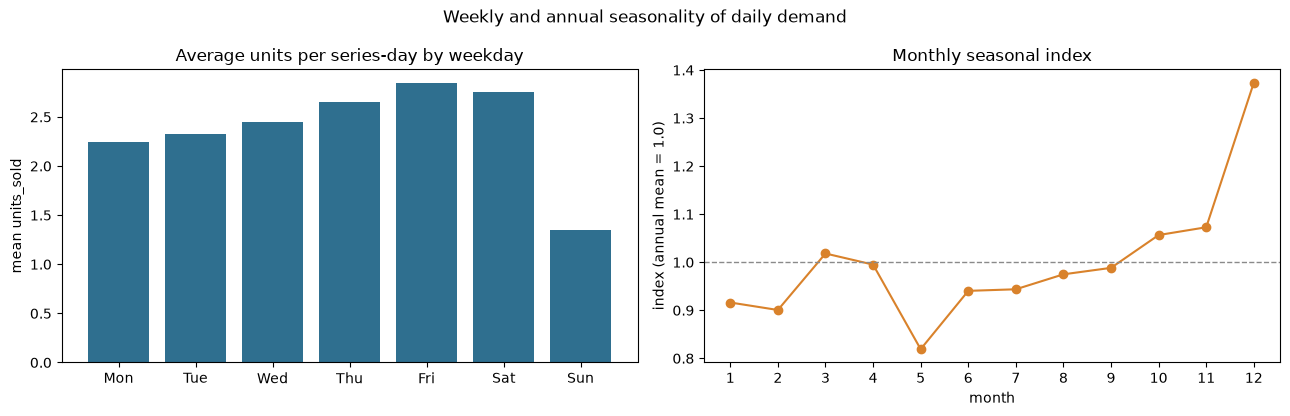

In [8]:
if plots_available():
    figure, axes = plt.subplots(1, 2, figsize=(13, 4.2))

    axes[0].bar(weekly_profile.index, weekly_profile.values, color=COLOR_MAIN)
    axes[0].set_title("Average units per series-day by weekday")
    axes[0].set_ylabel("mean units_sold")

    axes[1].plot(monthly_index.index, monthly_index.values, marker="o", color=COLOR_ACCENT)
    axes[1].axhline(1.0, color=COLOR_MUTED, linestyle="--", linewidth=1)
    axes[1].set_xticks(range(1, 13))
    axes[1].set_xlabel("month")
    axes[1].set_ylabel("index (annual mean = 1.0)")
    axes[1].set_title("Monthly seasonal index")

    figure.suptitle("Weekly and annual seasonality of daily demand")
    figure.tight_layout()
    plt.show()
else:
    print(seasonality.to_string())
    print(monthly_index.round(3).to_string())

Demand peaks Thursday–Saturday and collapses on Sunday; December runs well
above the annual average while May is the soft month. For inventory this means:
receiving and production should land before Thursday, December stock must be built in
November, and May is the natural window to postpone purchase orders and drain safety
stock. A uniform weeks-of-cover target ignores both effects.

## 3. ABC / XYZ portfolio analysis

**ABC** uses the `abc_class` already assigned in the product master (volume/value
ranking). **XYZ** is computed here from weekly demand variability using the classic
coefficients of variation bands: `X <= 0.50`, `0.50 < Y <= 1.00`, `Z > 1.00`.

Weekly buckets are used because daily zero-inflation inflates the coefficient of
variation: at daily grain every product would look erratic, hiding the real
difference between steady and intermittent items. The daily CV is kept as context.

In [9]:
product_profile = (
    daily.groupby(["product_id", "category", "abc_class", "demand_pattern"])
    .agg(
        units_sold=("units_sold", "sum"),
        revenue_mxn=("revenue_mxn", "sum"),
        mean_daily_units=("units_sold", "mean"),
        std_daily_units=("units_sold", "std"),
        zero_sale_share=("units_sold", lambda values: float((values == 0).mean())),
        stockout_share=("stockout_flag", "mean"),
    )
    .reset_index()
)
product_profile["daily_cv"] = (
    product_profile["std_daily_units"] / product_profile["mean_daily_units"].replace(0.0, np.nan)
)

weekly_units = (
    daily.assign(week=daily["date"].dt.to_period("W-SUN").dt.start_time)
    .groupby(["product_id", "week"])["units_sold"]
    .sum()
    .reset_index()
)
weekly_cv = weekly_units.groupby("product_id")["units_sold"].agg(["mean", "std"]).reset_index()
weekly_cv["weekly_cv"] = weekly_cv["std"] / weekly_cv["mean"].replace(0.0, np.nan)
product_profile = product_profile.merge(weekly_cv[["product_id", "weekly_cv"]], on="product_id", how="left")

XYZ_THRESHOLDS = (0.50, 1.00)


def classify_xyz(cv: float) -> str:
    # Weekly CV bands: X steady, Y variable/seasonal, Z erratic.
    if pd.isna(cv):
        return "Z"
    if cv <= XYZ_THRESHOLDS[0]:
        return "X"
    if cv <= XYZ_THRESHOLDS[1]:
        return "Y"
    return "Z"


product_profile["xyz_class"] = product_profile["weekly_cv"].map(classify_xyz)
product_profile["unit_share"] = product_profile["units_sold"] / product_profile["units_sold"].sum()
product_profile["revenue_share"] = product_profile["revenue_mxn"] / product_profile["revenue_mxn"].sum()
product_profile = product_profile.sort_values(
    ["units_sold", "product_id"], ascending=[False, True]
).reset_index(drop=True)

abc_revenue = product_profile.groupby("abc_class").agg(
    products=("product_id", "nunique"),
    units_sold=("units_sold", "sum"),
    revenue_mxn=("revenue_mxn", "sum"),
)
abc_revenue["unit_share"] = abc_revenue["units_sold"] / abc_revenue["units_sold"].sum()
abc_revenue["revenue_share"] = abc_revenue["revenue_mxn"] / abc_revenue["revenue_mxn"].sum()
abc_revenue.round(4)

,products,units_sold,revenue_mxn,unit_share,revenue_share
abc_class,,,,,
A,3,84279.00,1204664.08,0.5404,0.1969
B,4,38227.77,1346621.46,0.2451,0.2200
C,13,33453.43,3568382.80,0.2145,0.5831


In [10]:
abc_xyz = pd.crosstab(
    product_profile["abc_class"],
    product_profile["xyz_class"],
    margins=True,
    margins_name="Total",
).reindex(["A", "B", "C", "Total"])
abc_xyz

xyz_class,X,Y,Total
abc_class,,,
A,3,0,3
B,4,0,4
C,6,7,13
Total,13,7,20


In [11]:
product_profile[
    [
        "product_id",
        "category",
        "abc_class",
        "xyz_class",
        "units_sold",
        "unit_share",
        "revenue_share",
        "daily_cv",
        "weekly_cv",
        "zero_sale_share",
    ]
].head(12).round(4)

,product_id,category,abc_class,xyz_class,units_sold,unit_share,revenue_share,daily_cv,weekly_cv,zero_sale_share
0,P-007,Producto Terminado,A,X,37235.00,0.2387,0.0204,0.6102,0.1954,0.0395
1,P-008,Producto Terminado,A,X,24023.00,0.1540,0.0191,0.6421,0.1927,0.0520
2,P-012,Producto Terminado,A,X,23021.00,0.1476,0.1573,0.6515,0.2151,0.0477
3,P-017,Materia Prima,B,X,16067.77,0.1030,0.0434,0.7150,0.2208,0.0654
4,P-020,Consumibles,B,X,8211.00,0.0526,0.0028,1.4480,0.3479,0.6083
5,P-013,Producto Terminado,B,X,7670.00,0.0492,0.1454,1.4936,0.3296,0.6226
6,P-016,Producto Terminado,B,X,6279.00,0.0403,0.0284,1.6224,0.4130,0.6569
7,P-010,Producto Terminado,C,X,5600.00,0.0359,0.1549,1.6797,0.4050,0.6712
8,P-009,Producto Terminado,C,X,4591.00,0.0294,0.1831,0.9417,0.2640,0.3005
9,P-018,Consumibles,C,X,4340.00,0.0278,0.0048,1.8385,0.3802,0.7077


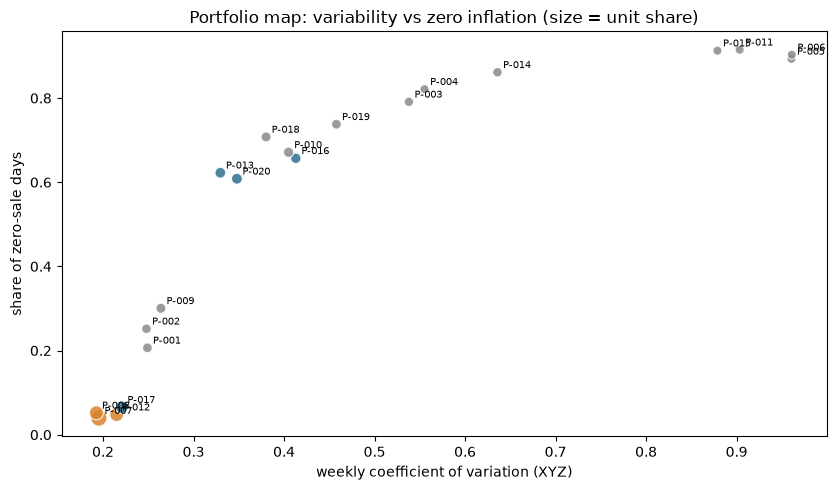

In [12]:
if plots_available():
    colors = product_profile["abc_class"].map(
        {"A": COLOR_ACCENT, "B": COLOR_MAIN, "C": COLOR_MUTED}
    )
    sizes = 40.0 + 400.0 * product_profile["unit_share"]

    figure, ax = plt.subplots(figsize=(8.5, 5))
    ax.scatter(
        product_profile["weekly_cv"],
        product_profile["zero_sale_share"],
        s=sizes,
        c=colors,
        alpha=0.85,
        edgecolor="white",
        linewidth=0.8,
    )
    for row in product_profile.itertuples():
        if np.isfinite(row.weekly_cv) and np.isfinite(row.zero_sale_share):
            ax.annotate(
                row.product_id,
                (row.weekly_cv, row.zero_sale_share),
                xytext=(4, 3),
                textcoords="offset points",
                fontsize=7,
            )
    ax.set_xlabel("weekly coefficient of variation (XYZ)")
    ax.set_ylabel("share of zero-sale days")
    ax.set_title("Portfolio map: variability vs zero inflation (size = unit share)")
    figure.tight_layout()
    plt.show()
else:
    print(product_profile[["product_id", "abc_class", "xyz_class", "weekly_cv"]].to_string(index=False))

The unit-based ABC ranking and the revenue ranking disagree. A/B items move most of the
units, while C products are lower-volume, higher-value items that carry most of the
revenue. XYZ confirms that A/B items are steady at weekly grain (all X), while
variability concentrates in C items (mostly Y). Inventory policy should protect A/B
service with tight controls, but it cannot treat C as cheap to ignore: C concentrates
revenue and needs availability and working-capital discipline even when its service
priority is lower by volume.

## 4. Zero-sale share by demand pattern

The generator labels every product as `smooth`, `intermittent` or `lumpy`. This table
checks that the labels match the observed zero-sale behaviour and shows the average
size of a sale when one occurs.

In [13]:
zero_by_pattern = (
    daily.groupby("demand_pattern")
    .agg(
        series_days=("units_sold", "size"),
        zero_days=("units_sold", lambda values: int((values == 0).sum())),
        zero_sale_share=("units_sold", lambda values: float((values == 0).mean())),
        mean_units_when_sold=(
            "units_sold",
            lambda values: float(values[values > 0].mean()) if (values > 0).any() else 0.0,
        ),
        stockout_share=("stockout_flag", "mean"),
    )
    .reindex(["smooth", "intermittent", "lumpy"])
)
zero_by_pattern.round(4)

,series_days,zero_days,zero_sale_share,mean_units_when_sold,stockout_share
demand_pattern,,,,,
smooth,23016,3168,0.1376,5.6060,0.0070
intermittent,26304,18468,0.7021,4.9544,0.0309
lumpy,16440,14747,0.8970,3.4664,0.0648


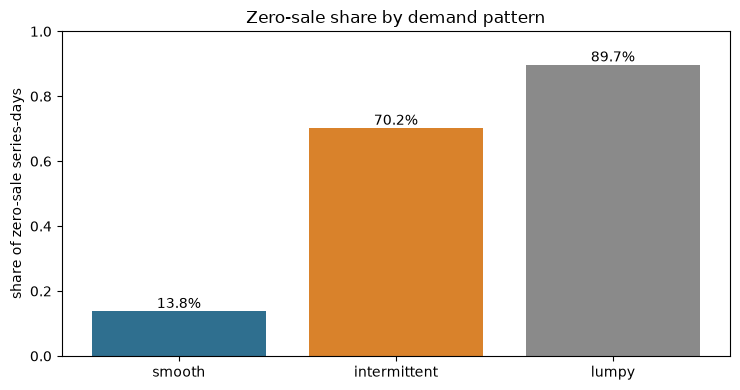

In [14]:
if plots_available():
    figure, ax = plt.subplots(figsize=(7.5, 4))
    bars = ax.bar(
        zero_by_pattern.index,
        zero_by_pattern["zero_sale_share"],
        color=[COLOR_MAIN, COLOR_ACCENT, COLOR_MUTED],
    )
    ax.bar_label(bars, labels=[f"{value:.1%}" for value in zero_by_pattern["zero_sale_share"]])
    ax.set_ylim(0.0, 1.0)
    ax.set_ylabel("share of zero-sale series-days")
    ax.set_title("Zero-sale share by demand pattern")
    figure.tight_layout()
    plt.show()
else:
    print(zero_by_pattern[["zero_sale_share"]].to_string())

Smooth items sell on most days, whereas lumpy items are silent almost nine days
out of ten. Consequence for forecasting: a median forecast of zero is statistically
correct for most lumpy days, but it is useless as a replenishment trigger. Lumpy and
intermittent series need quantile-based buffers (p90) and frequent review; smooth
series can be planned from the central forecast.

## 5. Pending orders and cancellations

`pending_units` counts orders created that day that are not yet invoiced (status
`pendiente` or `convertida`); they are committed demand and a leading indicator, but
they are not part of `units_sold`. `cancelled_units` are excluded from sales and
revenue, so the cancellation rate is expressed over gross demand
(`units_sold + cancelled_units`).

In [15]:
pending_by_pattern = (
    daily.groupby("demand_pattern")
    .agg(
        units_sold=("units_sold", "sum"),
        pending_units=("pending_units", "sum"),
        cancelled_units=("cancelled_units", "sum"),
    )
    .reindex(["smooth", "intermittent", "lumpy"])
)
pending_by_pattern["pending_to_sales"] = pending_by_pattern["pending_units"] / pending_by_pattern["units_sold"]
pending_by_pattern["cancellation_rate"] = pending_by_pattern["cancelled_units"] / (
    pending_by_pattern["units_sold"] + pending_by_pattern["cancelled_units"]
)
pending_by_pattern.round(4)

,units_sold,pending_units,cancelled_units,pending_to_sales,cancellation_rate
demand_pattern,,,,,
smooth,111268.63,9650.59,2142.52,0.0867,0.0189
intermittent,38823.00,3446.00,844.00,0.0888,0.0213
lumpy,5868.57,650.15,78.59,0.1108,0.0132


In [16]:
pending_by_category = (
    daily.groupby("category")
    .agg(
        units_sold=("units_sold", "sum"),
        pending_units=("pending_units", "sum"),
        cancelled_units=("cancelled_units", "sum"),
    )
    .sort_values("pending_units", ascending=False)
)
pending_by_category["pending_to_sales"] = pending_by_category["pending_units"] / pending_by_category["units_sold"]
pending_by_category["cancellation_rate"] = pending_by_category["cancelled_units"] / (
    pending_by_category["units_sold"] + pending_by_category["cancelled_units"]
)
pending_by_category.round(4)

,units_sold,pending_units,cancelled_units,pending_to_sales,cancellation_rate
category,,,,,
Producto Terminado,116037.00,10164.00,2235.00,0.0876,0.0189
Materia Prima,26700.66,2428.40,575.47,0.0909,0.0211
Consumibles,12551.00,1094.00,242.00,0.0872,0.0189
Insumos,671.54,60.34,12.64,0.0899,0.0185


In [17]:
cancellations_by_product = (
    daily.groupby(["product_id", "category"])
    .agg(
        units_sold=("units_sold", "sum"),
        cancelled_units=("cancelled_units", "sum"),
        cancelled_days=("cancelled_units", lambda values: int((values > 0).sum())),
    )
    .reset_index()
)
cancellations_by_product["cancellation_rate"] = cancellations_by_product["cancelled_units"] / (
    cancellations_by_product["units_sold"] + cancellations_by_product["cancelled_units"]
)
cancellations_by_product.sort_values("cancelled_units", ascending=False).head(10).round(4)

,product_id,category,units_sold,cancelled_units,cancelled_days,cancellation_rate
6,P-007,Producto Terminado,37235.00,755.00,67,0.0199
7,P-008,Producto Terminado,24023.00,437.00,59,0.0179
16,P-017,Materia Prima,16067.77,384.09,62,0.0233
11,P-012,Producto Terminado,23021.00,358.00,54,0.0153
12,P-013,Producto Terminado,7670.00,234.00,39,0.0296
15,P-016,Producto Terminado,6279.00,149.00,23,0.0232
19,P-020,Consumibles,8211.00,147.00,23,0.0176
9,P-010,Producto Terminado,5600.00,101.00,23,0.0177
17,P-018,Consumibles,4340.00,95.00,19,0.0214
8,P-009,Producto Terminado,4591.00,91.00,48,0.0194


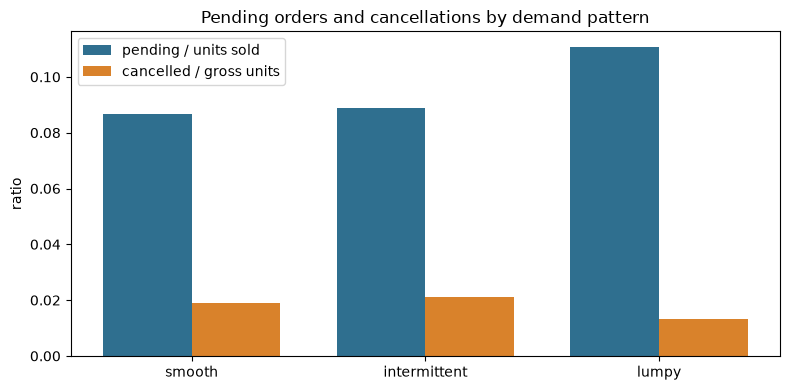

In [18]:
if plots_available():
    positions = np.arange(len(pending_by_pattern))
    width = 0.38
    figure, ax = plt.subplots(figsize=(8, 4))
    ax.bar(
        positions - width / 2,
        pending_by_pattern["pending_to_sales"],
        width,
        label="pending / units sold",
        color=COLOR_MAIN,
    )
    ax.bar(
        positions + width / 2,
        pending_by_pattern["cancellation_rate"],
        width,
        label="cancelled / gross units",
        color=COLOR_ACCENT,
    )
    ax.set_xticks(positions, pending_by_pattern.index)
    ax.set_ylabel("ratio")
    ax.set_title("Pending orders and cancellations by demand pattern")
    ax.legend()
    figure.tight_layout()
    plt.show()
else:
    print(pending_by_pattern[["pending_to_sales", "cancellation_rate"]].to_string())

Pending demand is roughly 9% of invoiced volume and is highest for lumpy
items and raw materials. Cancellations are small (~2% of gross units), so the sales
target does not need a cancellation adjustment at panel level; still, cancellation
rate should be tracked per product because a product with a high rate is losing
revenue that the demand model never sees. Stockout days (~3% of series-days) are the
larger measurement risk: on those days `units_sold` is censored, so the model learns
a lower demand level than the market actually requested.

## 6. Findings for inventory policy

1. **Zero inflation is structural, not a data bug.** About 55% of series-days have no
   sale (smooth ≈14%, intermittent ≈70%, lumpy ≈90%). A p50 forecast will be zero on
   many lumpy days; replenishment for those items must be driven by an upper quantile
   (p90) and frequent review, otherwise service collapses while inventory still looks
   adequate on paper.

2. **Seasonality is strong enough to schedule operations.** Thursday–Saturday carry
   roughly 1.1–1.2× the average day, Sunday only ≈0.57×; December is ≈1.37× the annual
   mean and May ≈0.82×. Receiving should land before the weekly peak, December stock
   must be built in November, and May is the right window to delay purchase orders.

3. **ABC by units is not ABC by value.** The three A products hold ≈54% of units but
   only ≈20% of revenue (high-volume, lower value per unit), while the 13 C products
   hold ≈21% of units and ≈58% of revenue (lower-volume, higher value). Tight service
   levels by volume belong to A/B; C needs value-based availability and working-capital
   controls, not neglect.

4. **Weekly XYZ separates planning methods.** All A/B products are X (weekly CV ≤0.5),
   while variability concentrates in C products (mostly Y). Forecast-driven planning
   is reliable for A/B; C/Y items need wider p90 buffers or periodic-review policies,
   because their daily CV is several times their weekly CV.

5. **Pending orders are a leading indicator; cancellations are a quality KPI.**
   Pending units run at ≈8.8% of sales (≈11% for lumpy items, ≈9% for raw materials)
   and should feed the working-capital/demand outlook. Cancellations are only ≈1.9%
   of gross demand, but stockouts (≈3.1% of series-days, higher for C) censor observed
   sales and bias the model downward — monitor them together.

**Next:** `02_modeling.ipynb` evaluates the quantile XGBoost champion against the
naive-seasonal and Croston-SBA baselines on the 28-day holdout.